## CE2 Phase 9: Classification of Life-Stage Age Groups

### 1. Problem Reformulation: Continuous Regression vs. Discrete Life-Stages
In biometric face analysis, predicting exact chronological age (e.g., distinguishing 27 from 28 years) is often an ill-posed and unnecessarily granular task. In practical applications—such as demographic verification, content rating, retail marketing, and access control—the operational objective is coarser: determining an individual's broad **life-stage cohort**.

To investigate supervised classification, chronological age is discretized into **5 ordered life-stage classes**:
1. **0–12 (Child):** Class Code `0` — Early developmental facial proportions.
2. **13–19 (Adolescent):** Class Code `1` — Pubertal skeletal and soft-tissue transitions.
3. **20–39 (Young Adult):** Class Code `2` — Mature adult cranial features; dominant demographic cohort.
4. **40–59 (Middle-Aged Adult):** Class Code `3` — Initial visible aging, skin elasticity changes.
5. **60+ (Senior):** Class Code `4` — Advanced facial aging patterns.

---

### 2. Methodological Trade-Offs & Inherent Constraints
* **Loss of Ordinal Granularity:** Grouping collapses all internal variance within a cohort; predicting age 21 for a 38-year-old is considered a "correct" match within the 20–39 class.
* **Boundary Penalty:** Hard class boundaries arbitrarily penalize borderline cases. A model predicting age 20 for a 19-year-old suffers a full misclassification penalty, despite being off by only one calendar year.
* **Class Imbalance:** Natural population and biometric web datasets exhibit heavy skew toward young adults (20–39), creating an asymmetric prior distribution.
* **Adjacent Accuracy:** To account for boundary effects, we also evaluate *Adjacent Accuracy*—the proportion of predictions landing either in the exact true cohort or an immediately adjacent neighbor ($|\hat{y} - y| \le 1$).

---

### 3. Evaluation Metrics in Plain Language
Given the skewed class distribution, raw accuracy is vulnerable to majority-class exploitation. We therefore emphasize class-balanced metrics:

* **Accuracy:** The overall proportion of test instances correctly classified: $\frac{\text{Correct Predictions}}{\text{Total Instances}}$.
* **Precision (Macro):** For each class, what fraction of predictions were genuinely correct? Macro-averaging computes the unweighted arithmetic mean across all 5 classes.
* **Recall (Macro):** For each class, what fraction of true members were successfully detected? Critical for identifying underrepresented cohorts (e.g., Adolescents, Seniors).
* **Macro-F1 Score (Primary Metric):** The unweighted harmonic mean of Macro-Precision and Macro-Recall:
  $$\text{Macro-F1} = \frac{1}{C} \sum_{c=1}^C \frac{2 \times \text{Precision}_c \times \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$
  Treats every life stage with equal importance, preventing trivial majority-class guessing from scoring high.
* **Confusion Matrix:** A $5 \times 5$ contingency table where rows represent true ground-truth cohorts and columns represent predicted cohorts, exposing exact cross-class confusion patterns.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, balanced_accuracy_score)

# Ensure relative paths work from project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Load existing unscaled train/test splits (maintaining exact CE1/CE2 partition)
X_train = pd.read_csv("data/processed/X_train.csv")
X_test = pd.read_csv("data/processed/X_test.csv")
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
y_test = pd.read_csv("data/processed/y_test.csv")["age"]

# Define feature partitions
continuous_cols = [
    'eye_distance', 'mouth_width', 'face_width', 'face_height',
    'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio'
]
dummy_cols = ['gender_1', 'race_1', 'race_2', 'race_3', 'race_4']

# Drop reference categories (gender_0, race_0) to prevent the dummy variable trap
X_train = X_train.drop(columns=["gender_0", "race_0"])
X_test = X_test.drop(columns=["gender_0", "race_0"])

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")


X_train shape: (2398, 12)
X_test shape:  (600, 12)
y_train shape: (2398,)
y_test shape:  (600,)



Life-Stage Class Distribution (Train vs. Test):
 Class_Index Life_Stage  Train_Count  Train_Pct  Test_Count  Test_Pct
           0       0-12          357      14.89          93     15.50
           1      13-19          125       5.21          28      4.67
           2      20-39         1179      49.17         278     46.33
           3      40-59          477      19.89         114     19.00
           4        60+          260      10.84          87     14.50

Majority Class: '20-39' (Index 2)
Baseline Accuracy (always predicting majority class on test set): 46.33% (0.4633)



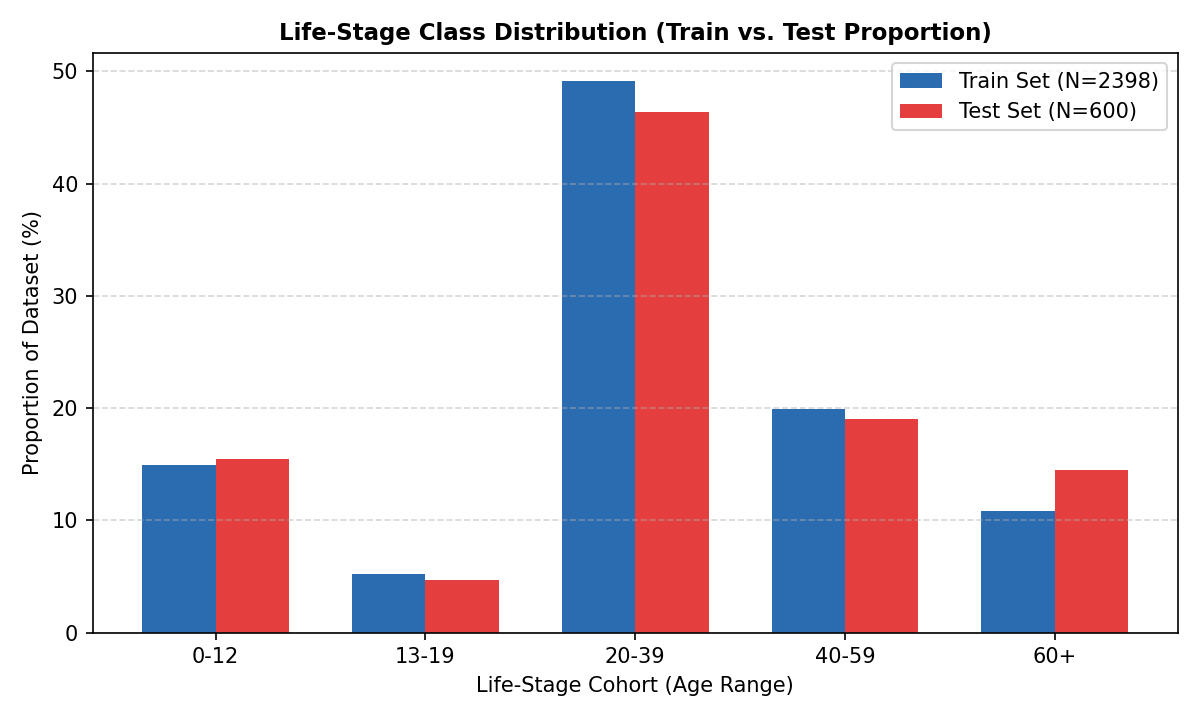

In [2]:
# Define age boundaries and corresponding cohort labels
bins = [0, 12, 19, 39, 59, 200]
class_names = ["0-12", "13-19", "20-39", "40-59", "60+"]

# Discretize continuous age into integer codes 0-4
y_train_c = pd.cut(y_train, bins=bins, labels=False).astype(int)
y_test_c = pd.cut(y_test, bins=bins, labels=False).astype(int)

# Verify no missing or unassigned class codes
assert y_train_c.isna().sum() == 0, "Missing class labels found in training set!"
assert y_test_c.isna().sum() == 0, "Missing class labels found in test set!"

# Tabulate class distributions
train_counts = y_train_c.value_counts().sort_index()
test_counts = y_test_c.value_counts().sort_index()

df_distribution = pd.DataFrame({
    "Class_Index": range(len(class_names)),
    "Life_Stage": class_names,
    "Train_Count": train_counts.values,
    "Train_Pct": (train_counts.values / len(y_train_c)) * 100,
    "Test_Count": test_counts.values,
    "Test_Pct": (test_counts.values / len(y_test_c)) * 100
})

print("Life-Stage Class Distribution (Train vs. Test):")
print(df_distribution.round(2).to_string(index=False))

# Majority class baseline reference
majority_class_idx = train_counts.idxmax()
majority_class_share = df_distribution.loc[df_distribution["Class_Index"] == majority_class_idx, "Test_Pct"].values[0]
print(f"\nMajority Class: '{class_names[majority_class_idx]}' (Index {majority_class_idx})")
print(f"Baseline Accuracy (always predicting majority class on test set): {majority_class_share:.2f}% ({majority_class_share/100:.4f})")

# Visual comparison: Train vs Test class percentages
fig, ax = plt.subplots(figsize=(8, 4.8))
x_indices = np.arange(len(class_names))
bar_width = 0.35

ax.bar(x_indices - bar_width/2, df_distribution["Train_Pct"], width=bar_width, color="#2b6cb0", label="Train Set (N=2398)")
ax.bar(x_indices + bar_width/2, df_distribution["Test_Pct"], width=bar_width, color="#e53e3e", label="Test Set (N=600)")

ax.set_title("Life-Stage Class Distribution (Train vs. Test Proportion)", fontsize=11, fontweight="bold")
ax.set_xlabel("Life-Stage Cohort (Age Range)", fontsize=10)
ax.set_ylabel("Proportion of Dataset (%)", fontsize=10)
ax.set_xticks(x_indices)
ax.set_xticklabels(class_names)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
ax.legend(frameon=True)
plt.tight_layout()

plt.savefig("visualizations/17_class_distribution.png", dpi=150)
plt.show()


In [3]:
# Define preprocessing column transformer
prep = ColumnTransformer([
    ("scale", StandardScaler(), continuous_cols),
    ("dummies", "passthrough", dummy_cols)
])

# Define standard Stratified K-Fold CV (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Helper function to fit and evaluate a classifier on holdout test data
def evaluate_clf(model, name):
    model.fit(X_train, y_train_c)
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    test_acc = accuracy_score(y_test_c, y_pred)
    bal_acc = balanced_accuracy_score(y_test_c, y_pred)
    prec_macro = precision_score(y_test_c, y_pred, average="macro", zero_division=0)
    rec_macro = recall_score(y_test_c, y_pred, average="macro", zero_division=0)
    f1_m = f1_score(y_test_c, y_pred, average="macro", zero_division=0)
    f1_w = f1_score(y_test_c, y_pred, average="weighted", zero_division=0)
    
    # Adjacent accuracy: fraction of predictions within +/- 1 class of ground truth
    adj_acc = np.mean(np.abs(y_pred - y_test_c) <= 1)
    
    return {
        "Model": name,
        "Test_Accuracy": test_acc,
        "Balanced_Accuracy": bal_acc,
        "Precision_macro": prec_macro,
        "Recall_macro": rec_macro,
        "F1_macro": f1_m,
        "F1_weighted": f1_w,
        "Adjacent_Accuracy": adj_acc
    }

print("Evaluation helper 'evaluate_clf' and StratifiedKFold cross-validator initialized.")


Evaluation helper 'evaluate_clf' and StratifiedKFold cross-validator initialized.



In [4]:
# Baseline Classifier: Always predict the most frequent training class (20-39)
dummy_baseline = DummyClassifier(strategy="most_frequent")
res_baseline = evaluate_clf(dummy_baseline, "Baseline (Most Frequent)")

df_base_res = pd.DataFrame([res_baseline])
print("Baseline Classifier Evaluation on Test Set:")
print(df_base_res.round(4).to_string(index=False))


Baseline Classifier Evaluation on Test Set:
                   Model  Test_Accuracy  Balanced_Accuracy  Precision_macro  Recall_macro  F1_macro  F1_weighted  Adjacent_Accuracy
Baseline (Most Frequent)         0.4633                0.2           0.0927           0.2    0.1267       0.2934                0.7



In [5]:
# Note: All hyperparameter sweeps are executed exclusively on TRAINING data via 5-fold Stratified CV.
# The test set is never accessed or consulted during tuning.

# 1. KNN Neighbor Sweep
k_candidates = [3, 5, 7, 11, 15, 21, 31, 51]
knn_sweep_rows = []

for k in k_candidates:
    pipe_knn = Pipeline([("prep", prep), ("clf", KNeighborsClassifier(n_neighbors=k))])
    cv_k = cross_validate(pipe_knn, X_train, y_train_c, cv=cv, scoring="f1_macro")
    knn_sweep_rows.append({
        "k": k,
        "CV_F1_Macro_Mean": np.mean(cv_k["test_score"]),
        "CV_F1_Macro_Std": np.std(cv_k["test_score"])
    })

df_knn_sweep = pd.DataFrame(knn_sweep_rows)
best_k = int(df_knn_sweep.loc[df_knn_sweep["CV_F1_Macro_Mean"].idxmax(), "k"])

print("KNN Neighbor Sweep (5-Fold Stratified CV on Training Data):")
print(df_knn_sweep.round(4).to_string(index=False))
print(f"Optimal KNN parameter: best_k = {best_k} (Mean Macro-F1 = {df_knn_sweep['CV_F1_Macro_Mean'].max():.4f})")

# 2. Decision Tree Max-Depth Sweep
depth_candidates = [2, 3, 4, 5, 6, 8, 10, None]
dt_sweep_rows = []

for d in depth_candidates:
    clf_dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_d = cross_validate(clf_dt, X_train, y_train_c, cv=cv, scoring="f1_macro", return_train_score=True)
    dt_sweep_rows.append({
        "max_depth": str(d),
        "CV_F1_Macro_Mean": np.mean(cv_d["test_score"]),
        "CV_F1_Macro_Std": np.std(cv_d["test_score"]),
        "Train_F1_Macro_Mean": np.mean(cv_d["train_score"])
    })

df_dt_sweep = pd.DataFrame(dt_sweep_rows)
best_depth_str = df_dt_sweep.loc[df_dt_sweep["CV_F1_Macro_Mean"].idxmax(), "max_depth"]
best_depth = int(best_depth_str) if best_depth_str != "None" else None

print("\nDecision Tree Depth Sweep (5-Fold Stratified CV on Training Data):")
print(df_dt_sweep.round(4).to_string(index=False))
print(f"Optimal Decision Tree parameter: best_depth = {best_depth} (Mean Macro-F1 = {df_dt_sweep['CV_F1_Macro_Mean'].max():.4f})")


KNN Neighbor Sweep (5-Fold Stratified CV on Training Data):
 k  CV_F1_Macro_Mean  CV_F1_Macro_Std
 3            0.3168           0.0147
 5            0.3283           0.0194
 7            0.3349           0.0193
11            0.3298           0.0242
15            0.3212           0.0071
21            0.3123           0.0040
31            0.3142           0.0126
51            0.3044           0.0104
Optimal KNN parameter: best_k = 7 (Mean Macro-F1 = 0.3349)

Decision Tree Depth Sweep (5-Fold Stratified CV on Training Data):
max_depth  CV_F1_Macro_Mean  CV_F1_Macro_Std  Train_F1_Macro_Mean
        2            0.2584           0.0061               0.2602
        3            0.2586           0.0061               0.2608
        4            0.2573           0.0057               0.2678
        5            0.2815           0.0306               0.3117
        6            0.2803           0.0285               0.3517
        8            0.2995           0.0369               0.4896
       10

In [6]:
# Define candidate classification models
# Note on scaling:
# - Logistic Regression, KNN, and SVM require feature scaling because they depend directly on Euclidean
#   distances or gradient-based regularization penalties.
# - Decision Trees and Random Forests are invariant to monotonic feature scaling and operate on raw features.
# - Gaussian Naive Bayes assumes conditional feature independence and continuous Gaussian density, which
#   is only an approximation for binary demographic dummy variables.

models = {
    "Logistic Regression": Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    f"KNN (k={best_k})": Pipeline([
        ("prep", prep),
        ("clf", KNeighborsClassifier(n_neighbors=best_k))
    ]),
    "Decision Tree (unrestricted)": DecisionTreeClassifier(random_state=42),
    f"Decision Tree (depth={best_depth})": DecisionTreeClassifier(max_depth=best_depth, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "SVM (RBF)": Pipeline([
        ("prep", prep),
        ("clf", SVC(kernel="rbf", random_state=42))
    ])
}

print(f"Candidate model dictionary defined with {len(models)} algorithms.")


Candidate model dictionary defined with 7 algorithms.



In [7]:
# 5-fold stratified cross-validation on TRAINING data for all candidate models
cv_scoring = {"acc": "accuracy", "f1": "f1_macro"}
cv_results_rows = []

for model_name, model_obj in models.items():
    cv_res = cross_validate(model_obj, X_train, y_train_c, cv=cv, scoring=cv_scoring, return_train_score=True)
    cv_results_rows.append({
        "Model": model_name,
        "CV_Accuracy_Mean": np.mean(cv_res["test_acc"]),
        "CV_Accuracy_Std": np.std(cv_res["test_acc"]),
        "CV_F1_macro_Mean": np.mean(cv_res["test_f1"]),
        "CV_F1_macro_Std": np.std(cv_res["test_f1"]),
        "Train_F1_macro_Mean": np.mean(cv_res["train_f1"])
    })

df_cv_classification = pd.DataFrame(cv_results_rows)
print("5-Fold Stratified Cross-Validation Performance (Training Data Only):")
print(df_cv_classification.round(4).to_string(index=False))


5-Fold Stratified Cross-Validation Performance (Training Data Only):
                       Model  CV_Accuracy_Mean  CV_Accuracy_Std  CV_F1_macro_Mean  CV_F1_macro_Std  Train_F1_macro_Mean
         Logistic Regression            0.5684           0.0263            0.3319           0.0150               0.3326
                   KNN (k=7)            0.5279           0.0182            0.3349           0.0193               0.4716
Decision Tree (unrestricted)            0.4249           0.0286            0.3122           0.0297               1.0000
    Decision Tree (depth=10)            0.4925           0.0316            0.3322           0.0323               0.6418
               Random Forest            0.5534           0.0233            0.3365           0.0275               1.0000
      Naive Bayes (Gaussian)            0.4562           0.0068            0.3724           0.0110               0.3831
                   SVM (RBF)            0.5555           0.0081            0.2632          

In [8]:
# Fit each model on the full training set and evaluate on holdout test set
test_evaluation_rows = [res_baseline]

for model_name, model_obj in models.items():
    res_m = evaluate_clf(model_obj, model_name)
    test_evaluation_rows.append(res_m)

df_test_classification = pd.DataFrame(test_evaluation_rows)
print("Final Model Evaluation on Holdout Test Set:")
print(df_test_classification.round(4).to_string(index=False))

# Select best model based strictly on CV_F1_macro_Mean from training data cross-validation
best_model_idx = df_cv_classification["CV_F1_macro_Mean"].idxmax()
best_model_name = df_cv_classification.loc[best_model_idx, "Model"]
best_cv_f1 = df_cv_classification.loc[best_model_idx, "CV_F1_macro_Mean"]

print(f"\nBest Model Selection (Chosen by Training CV Macro-F1): '{best_model_name}'")
print(f"Reason: Achieved highest 5-fold CV Macro-F1 score ({best_cv_f1:.4f}) on training data, demonstrating superior balance across all life-stage cohorts.")

# Persist test results table to disk
df_test_classification.to_csv("data/processed/ce2_classification_results.csv", index=False)
print("Saved classification results to: data/processed/ce2_classification_results.csv")


Final Model Evaluation on Holdout Test Set:
                       Model  Test_Accuracy  Balanced_Accuracy  Precision_macro  Recall_macro  F1_macro  F1_weighted  Adjacent_Accuracy
    Baseline (Most Frequent)         0.4633             0.2000           0.0927        0.2000    0.1267       0.2934             0.7000
         Logistic Regression         0.5133             0.3217           0.2849        0.3217    0.2958       0.4419             0.7433
                   KNN (k=7)         0.4850             0.3239           0.3447        0.3239    0.3169       0.4475             0.7400
Decision Tree (unrestricted)         0.3933             0.2785           0.2731        0.2785    0.2749       0.3882             0.6900
    Decision Tree (depth=10)         0.4600             0.3110           0.3134        0.3110    0.3036       0.4290             0.7383
               Random Forest         0.5250             0.3395           0.3505        0.3395    0.3246       0.4670             0.7617
    

Detailed Classification Report for Naive Bayes (Gaussian):
              precision    recall  f1-score   support

        0-12       0.43      0.59      0.50        93
       13-19       0.00      0.00      0.00        28
       20-39       0.65      0.46      0.54       278
       40-59       0.35      0.41      0.38       114
         60+       0.26      0.36      0.30        87

    accuracy                           0.43       600
   macro avg       0.34      0.36      0.34       600
weighted avg       0.47      0.43      0.44       600




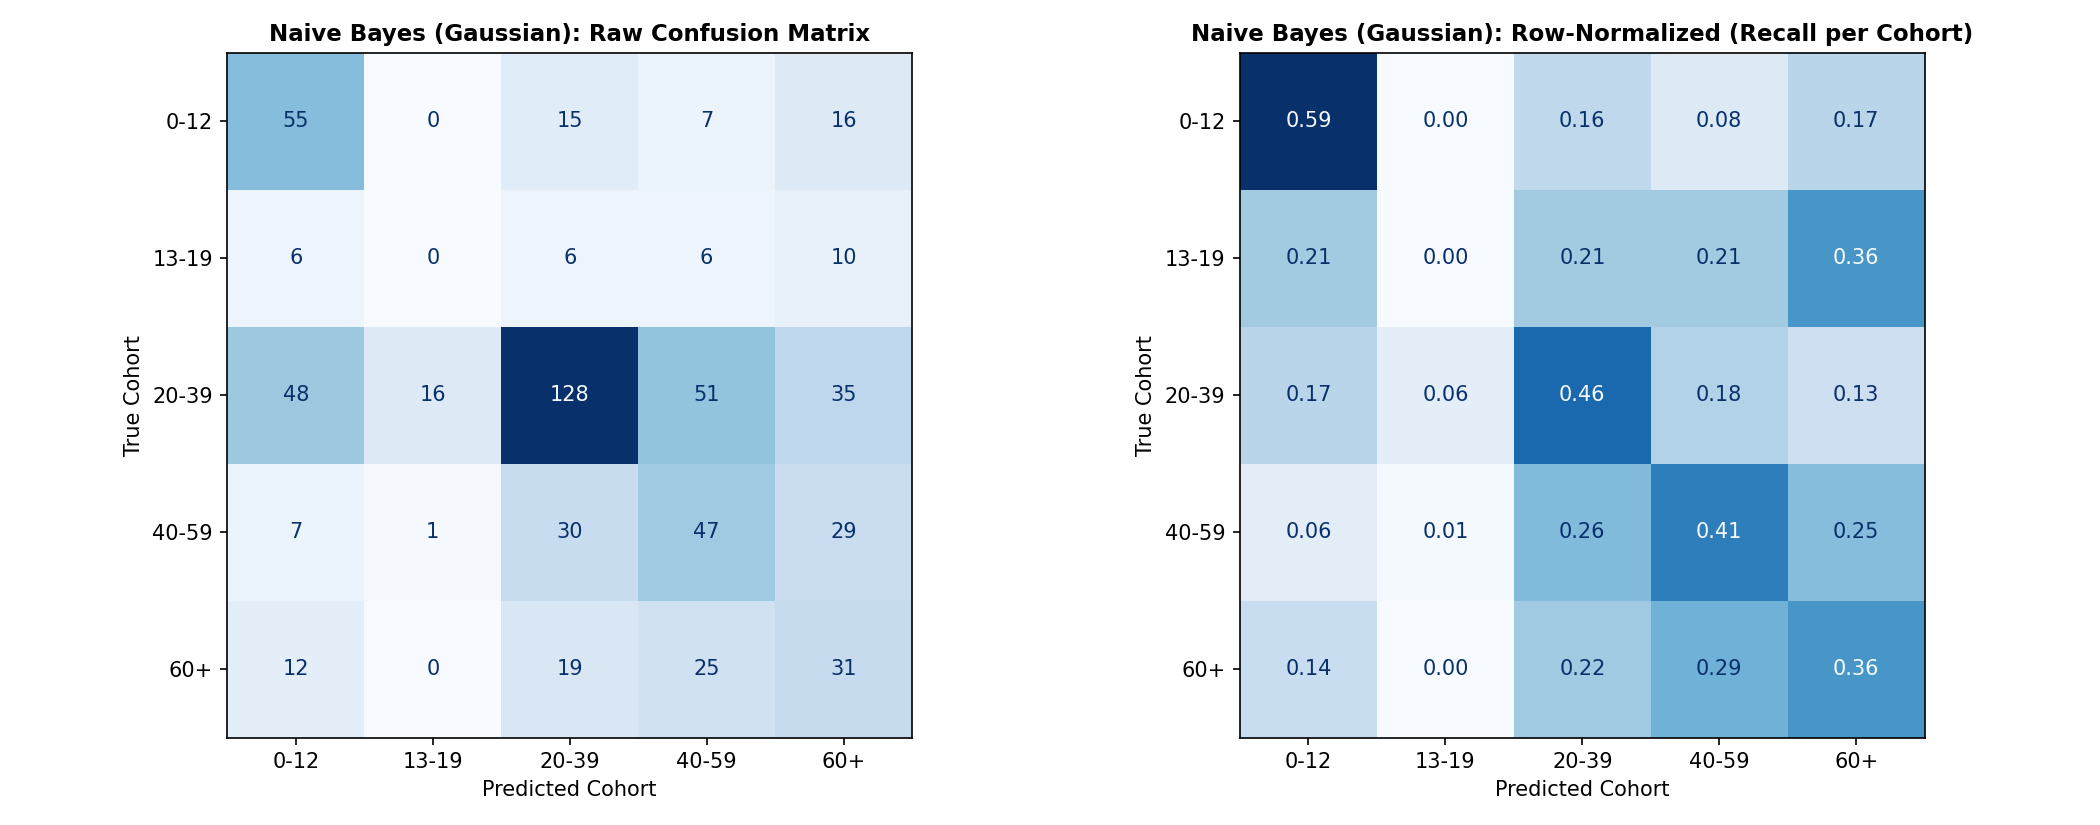

In [9]:
# Refit best model on training set and generate predictions on holdout test set
best_clf = models[best_model_name]
best_clf.fit(X_train, y_train_c)
y_pred_best = best_clf.predict(X_test)

# Plot Raw Counts and Row-Normalized Confusion Matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: Raw Counts Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_c, y_pred_best,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title(f"{best_model_name}: Raw Confusion Matrix", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Cohort", fontsize=10)
axes[0].set_ylabel("True Cohort", fontsize=10)

# Right: Row-Normalized Confusion Matrix (Recall per cohort)
ConfusionMatrixDisplay.from_predictions(
    y_test_c, y_pred_best,
    display_labels=class_names,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title(f"{best_model_name}: Row-Normalized (Recall per Cohort)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Predicted Cohort", fontsize=10)
axes[1].set_ylabel("True Cohort", fontsize=10)

plt.tight_layout()
plt.savefig("visualizations/18_confusion_matrix_best.png", dpi=150)
plt.show()

# Print detailed per-class classification report
print(f"Detailed Classification Report for {best_model_name}:")
print(classification_report(y_test_c, y_pred_best, target_names=class_names, zero_division=0))


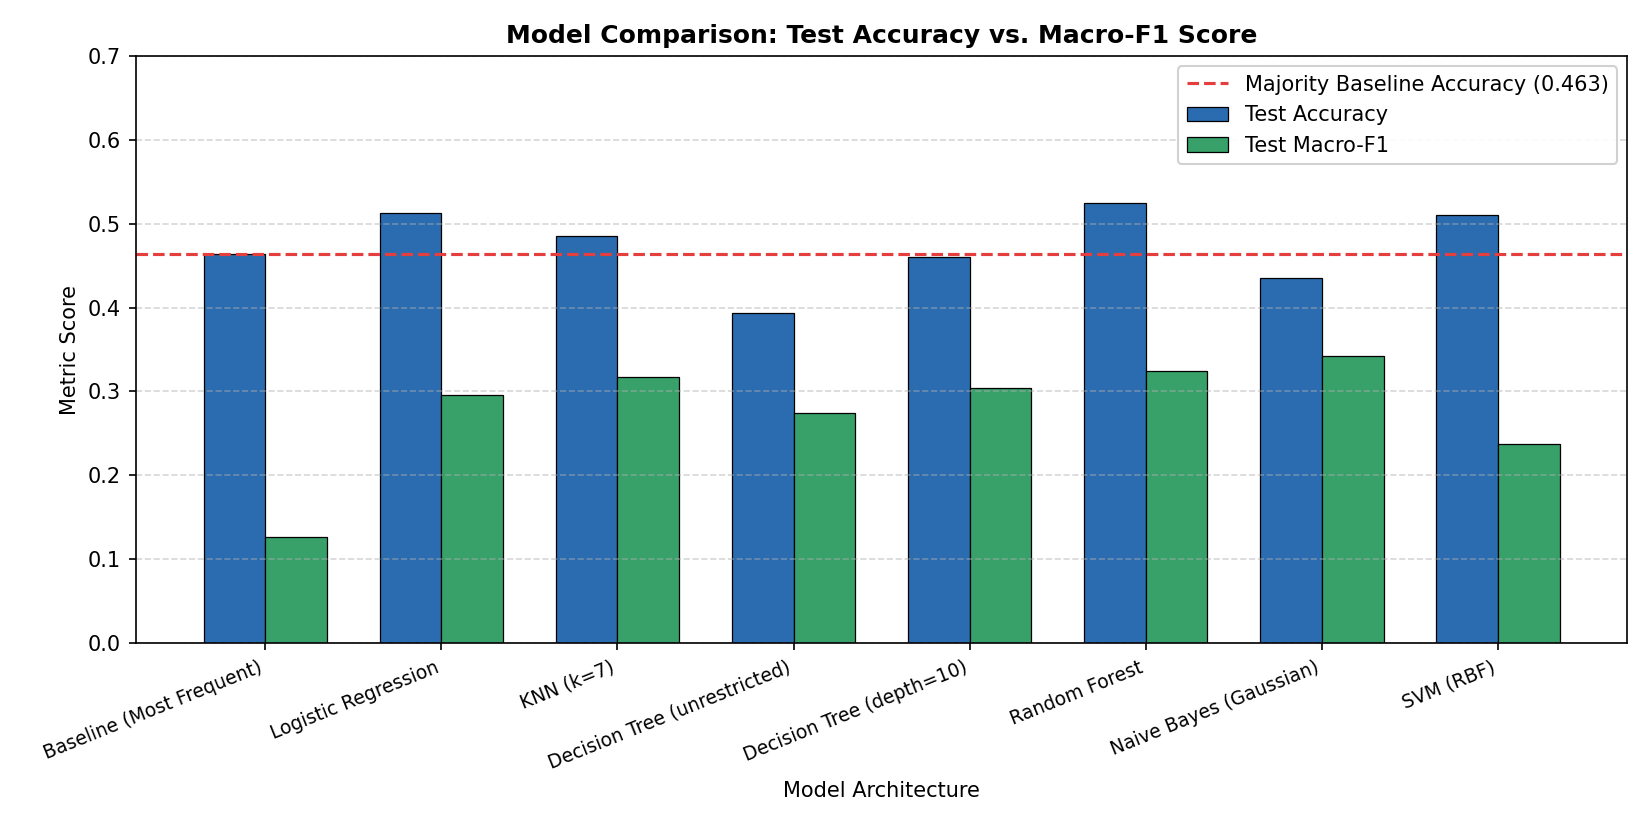

In [10]:
# Grouped bar chart of Test Accuracy and Macro-F1 across all models
model_labels = df_test_classification["Model"]
test_accuracies = df_test_classification["Test_Accuracy"]
macro_f1s = df_test_classification["F1_macro"]

x_pos = np.arange(len(model_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))

bars1 = ax.bar(x_pos - width/2, test_accuracies, width, label="Test Accuracy", color="#2b6cb0", edgecolor="black", linewidth=0.6)
bars2 = ax.bar(x_pos + width/2, macro_f1s, width, label="Test Macro-F1", color="#38a169", edgecolor="black", linewidth=0.6)

# Horizontal dashed line at baseline accuracy
baseline_acc = df_test_classification.loc[df_test_classification["Model"] == "Baseline (Most Frequent)", "Test_Accuracy"].values[0]
ax.axhline(baseline_acc, color="#e53e3e", linestyle="--", linewidth=1.5, label=f"Majority Baseline Accuracy ({baseline_acc:.3f})")

ax.set_title("Model Comparison: Test Accuracy vs. Macro-F1 Score", fontsize=12, fontweight="bold")
ax.set_xlabel("Model Architecture", fontsize=10)
ax.set_ylabel("Metric Score", fontsize=10)
ax.set_xticks(x_pos)
ax.set_xticklabels(model_labels, rotation=22, ha="right", fontsize=9)
ax.set_ylim(0, 0.7)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
ax.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper right")
plt.tight_layout()

plt.savefig("visualizations/19_classification_comparison.png", dpi=150)
plt.show()


In [11]:
# Regression-Then-Bin Benchmark:
# Fit Multiple Linear Regression on raw continuous age, predict continuous age, then bin into cohorts.
pipe_reg = Pipeline([("prep", prep), ("reg", LinearRegression())])
pipe_reg.fit(X_train, y_train)

# Predict raw continuous ages on test set
y_test_pred_raw = pipe_reg.predict(X_test)

# Clip predictions to prevent negative or extreme values outside the cohort bins
y_test_pred_clipped = np.clip(y_test_pred_raw, 0.5, 200.0)

# Discretize continuous predictions into the 5 cohorts
y_pred_reg_binned = pd.cut(y_test_pred_clipped, bins=bins, labels=False).astype(int)

# Evaluate using identical classification metrics
reg_binned_row = {
    "Model": "Multiple LR -> binned",
    "Test_Accuracy": accuracy_score(y_test_c, y_pred_reg_binned),
    "Balanced_Accuracy": balanced_accuracy_score(y_test_c, y_pred_reg_binned),
    "Precision_macro": precision_score(y_test_c, y_pred_reg_binned, average="macro", zero_division=0),
    "Recall_macro": recall_score(y_test_c, y_pred_reg_binned, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test_c, y_pred_reg_binned, average="macro", zero_division=0),
    "F1_weighted": f1_score(y_test_c, y_pred_reg_binned, average="weighted", zero_division=0),
    "Adjacent_Accuracy": np.mean(np.abs(y_pred_reg_binned - y_test_c) <= 1)
}

# Compare against Baseline and Best Classifier
df_comparison_3 = pd.DataFrame([
    res_baseline,
    df_test_classification.loc[df_test_classification["Model"] == best_model_name].iloc[0].to_dict(),
    reg_binned_row
])

print("Comparison: Baseline vs. Best Classifier vs. Regression-Then-Bin:")
print(df_comparison_3.round(4).to_string(index=False))

# Append regression-then-bin row to results file
df_results_current = pd.read_csv("data/processed/ce2_classification_results.csv")
df_results_updated = pd.concat([df_results_current, pd.DataFrame([reg_binned_row])], ignore_index=True)
df_results_updated.to_csv("data/processed/ce2_classification_results.csv", index=False)
print("\nAppended 'Multiple LR -> binned' row to data/processed/ce2_classification_results.csv")


Comparison: Baseline vs. Best Classifier vs. Regression-Then-Bin:
                   Model  Test_Accuracy  Balanced_Accuracy  Precision_macro  Recall_macro  F1_macro  F1_weighted  Adjacent_Accuracy
Baseline (Most Frequent)         0.4633             0.2000           0.0927        0.2000    0.1267       0.2934             0.7000
  Naive Bayes (Gaussian)         0.4350             0.3641           0.3356        0.3641    0.3419       0.4410             0.7067
   Multiple LR -> binned         0.4617             0.2697           0.3434        0.2697    0.2442       0.3944             0.7750

Appended 'Multiple LR -> binned' row to data/processed/ce2_classification_results.csv



Random Forest Gini Feature Importances:
            Feature  Importance
  face_aspect_ratio      0.1618
         face_width      0.1403
  eye_to_face_ratio      0.1250
        face_height      0.1234
mouth_to_face_ratio      0.1228
       eye_distance      0.1177
        mouth_width      0.1139
           gender_1      0.0256
             race_1      0.0234
             race_2      0.0191
             race_3      0.0157
             race_4      0.0113



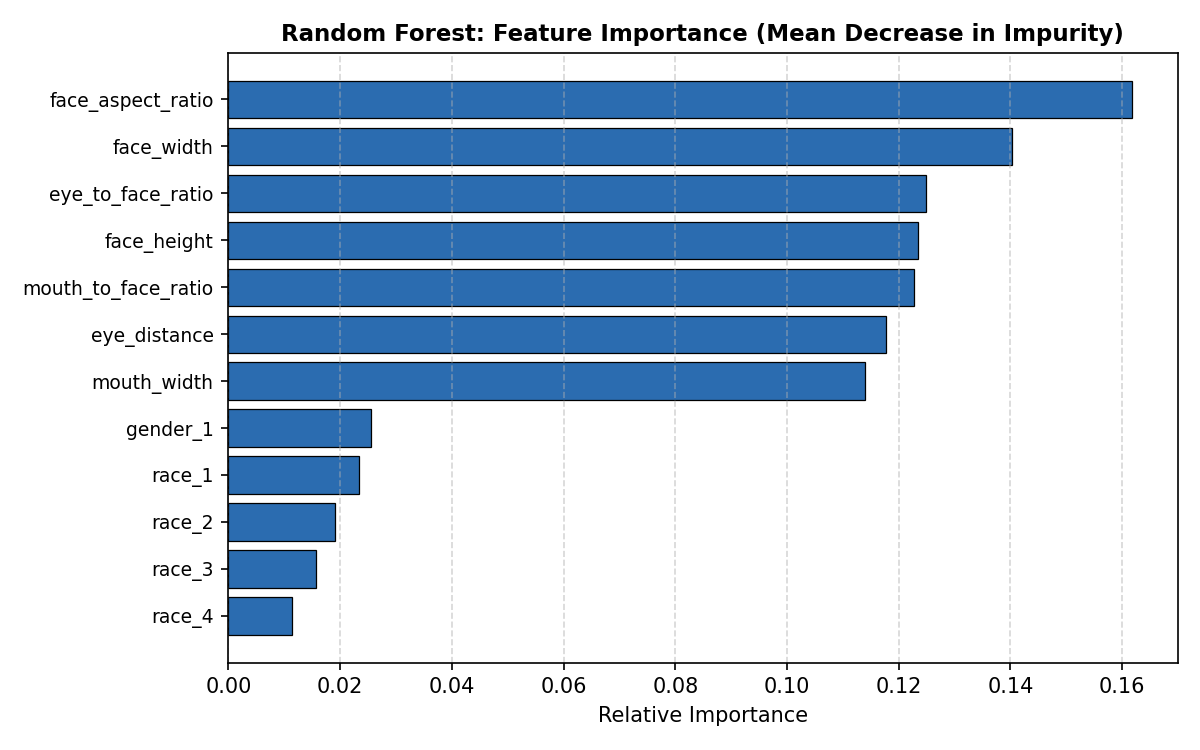

In [12]:
# Extract impurity-based feature importances from fitted Random Forest
rf_clf = models["Random Forest"]
rf_clf.fit(X_train, y_train_c)

# Feature names in order of X_train columns
feature_names = X_train.columns
importances = rf_clf.feature_importances_

df_importances = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("Random Forest Gini Feature Importances:")
print(df_importances.round(4).to_string(index=False))

# Plot horizontal bar chart
# Note: Impurity-based (MDI) importances can favor continuous features with many distinct values
# over binary demographic indicator variables, regardless of true predictive utility.
fig, ax = plt.subplots(figsize=(8, 5))
y_positions = np.arange(len(df_importances))

ax.barh(y_positions, df_importances["Importance"][::-1], color="#2b6cb0", edgecolor="black", linewidth=0.6)
ax.set_yticks(y_positions)
ax.set_yticklabels(df_importances["Feature"][::-1], fontsize=9)
ax.set_title("Random Forest: Feature Importance (Mean Decrease in Impurity)", fontsize=11, fontweight="bold")
ax.set_xlabel("Relative Importance", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5, axis="x")
plt.tight_layout()

plt.savefig("visualizations/20_rf_feature_importance.png", dpi=150)
plt.show()


In [13]:
# Cost-Sensitive Learning: Evaluate models with class_weight='balanced'
# This penalizes errors in underrepresented cohorts inversely proportional to class frequencies.
models_balanced = {
    "Logistic Regression (balanced)": Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "SVM (RBF) (balanced)": Pipeline([
        ("prep", prep),
        ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=42))
    ]),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1
    )
}

balanced_rows = []
for name, m in models_balanced.items():
    res = evaluate_clf(m, name)
    balanced_rows.append(res)

df_balanced = pd.DataFrame(balanced_rows)

# Comparison table: Unweighted vs. Balanced
comparison_pairs = [
    ("Logistic Regression", "Logistic Regression (balanced)"),
    ("SVM (RBF)", "SVM (RBF) (balanced)"),
    ("Random Forest", "Random Forest (balanced)")
]

comp_rows = []
for unweighted_name, balanced_name in comparison_pairs:
    row_unw = df_test_classification.loc[df_test_classification["Model"] == unweighted_name].iloc[0]
    row_bal = df_balanced.loc[df_balanced["Model"] == balanced_name].iloc[0]
    
    comp_rows.append({
        "Model": unweighted_name,
        "Test_Accuracy": row_unw["Test_Accuracy"],
        "Recall_macro": row_unw["Recall_macro"],
        "F1_macro": row_unw["F1_macro"]
    })
    comp_rows.append({
        "Model": balanced_name,
        "Test_Accuracy": row_bal["Test_Accuracy"],
        "Recall_macro": row_bal["Recall_macro"],
        "F1_macro": row_bal["F1_macro"]
    })

df_weight_comp = pd.DataFrame(comp_rows)
print("Unweighted vs. Class-Balanced Comparison on Holdout Test Set:")
print(df_weight_comp.round(4).to_string(index=False))

# Append balanced rows to results CSV
df_results_current = pd.read_csv("data/processed/ce2_classification_results.csv")
df_results_final = pd.concat([df_results_current, df_balanced], ignore_index=True)
df_results_final.to_csv("data/processed/ce2_classification_results.csv", index=False)
print("\nAppended balanced models to data/processed/ce2_classification_results.csv")


Unweighted vs. Class-Balanced Comparison on Holdout Test Set:
                         Model  Test_Accuracy  Recall_macro  F1_macro
           Logistic Regression         0.5133        0.3217    0.2958
Logistic Regression (balanced)         0.4100        0.3570    0.3451
                     SVM (RBF)         0.5100        0.2860    0.2376
          SVM (RBF) (balanced)         0.4133        0.3741    0.3486
                 Random Forest         0.5250        0.3395    0.3246
      Random Forest (balanced)         0.5033        0.3144    0.2963

Appended balanced models to data/processed/ce2_classification_results.csv



### Observation

*(This section is reserved for user observations and qualitative synthesis regarding life-stage classification boundaries, model trade-offs, confusion patterns, and class-weighting impacts.)*
